### Build a Basic Chatbot with LangGraph(Graph API)

#### Nodes — What task should be performed?
A Node is a Python function that performs a specific task in LangGraph.

For example, our Student Result Assistant has three tasks:
- Check the student's marks.
- Generate a pass message.
- Generate a fail message.
Each task can be represented by a node.

#### Edges — Which task should execute next?
An Edge is a connection between two nodes that determines the flow of execution.

LangGraph mainly uses two types of edges.

Type 1: Normal Edge : A normal edge always connects one node to the next without checking any condition.

Type 2: Conditional Edge : A conditional edge decides which node should execute based on a condition.

For example:
- Marks ≥ 35 → Pass node
- Marks below 35 → Fail node

#### State — What information is shared between nodes?

State is a shared data structure that stores information needed throughout the workflow.

Imagine a student has scored 75 marks.

The check_marks node needs the marks, and the pass_student node needs to store the final result.

Instead of passing separate variables manually between each function, LangGraph uses State.

Think of an AI agent as a restaurant.
- Node = Chef: Performs a task, such as preparing food.
- Edge = Waiter: Directs the order to the next station.
- State = Order Slip: Contains the order details that different people need.

Purpose: Annotated allows us to attach extra information or instructions to a Python type.

For example: from typing import Annotatedage: Annotated[int, "Age of the student"]

Here:
- int means the age should be an integer.
- "Age of the student" is additional metadata.


- Purpose: add_messages is a reducer that manages how messages are added to the chatbot's State.

In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import START,END,StateGraph
from langgraph.graph import add_messages

Whenever a node returns new messages, use add_messages to merge them into the existing message list.

Without a reducer like add_messages, the default behavior is to replace the existing value.

In [2]:
class State(TypedDict):
    #Messages have the type "list".The add_message function in the annotation
    # defines how this state key should be updated 
    # in this case , it appends messages to the list ,rather than overwriting them

    messages:Annotated[list,add_messages]

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')

In [6]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.5.0', 'langchain-groq': '1.2.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001D5437874D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001D543787E00>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [18]:
graph_builder = StateGraph(State)

In [ ]:
graph_builder.add_node("llmchatbot",chatbot)

graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

# Now compile() prepares the workflow so you can execute it.
graph = graph_builder.compile()

In [21]:
response = graph.invoke({"messages":"Hi"})

In [25]:
response['messages'][-1].content

'Hello! How can I assist you today?'

### Chatbot with tool

In [10]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)

tool.invoke("WHo is Luffy")

{'query': 'WHo is Luffy',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://onepiece.fandom.com/wiki/Monkey_D._Luffy',
   'title': 'Monkey D. Luffy | One Piece Wiki | Fandom',
   'content': 'Luffy is a young man who stands at 5\'9" feet tall (5\'8" pre-timeskip) with shaggy black hair with a small widow\'s peak, round black eyes, and a slim muscular build. Luffy\'s appearance is very similar to his grandfather Garp\'s as a young man, albeit a lot less muscular. He is renowned for his trademark yellow straw hat with a red hatband (from which he gets his epithet "Straw Hat Luffy"), which was lent to him when he was young by the legendary pirate captain, "Red-Haired" Shanks,\\ who in turn [...] Monkey D. Luffy, commonly known as "Straw Hat Luffy" or simply "Straw Hat",\\ is the founder and captain of the Straw Hat Pirates.\\\\ He pursues the legendary treasure of the late Gol D. Roger in order to become the new Pirate King\\ and reach a further, u

In [11]:
# Custom Function with Doc String

def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
    
        a (int): first int
        b (int): second int
    
    Returns:
        int : Output int
    """
    return a*b

In [12]:
from langgraph.graph import START,END,StateGraph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [13]:
tools = [tool,multiply]
llm_with_tools = llm.bind_tools(tools)

In [14]:
def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tools.invoke(state['messages'])]
    }

In [20]:
builder = StateGraph(State)

# Adding Nodes
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Adding Edges
builder.add_edge(START,'tool_calling_llm')
builder.add_conditional_edges(
    'tool_calling_llm',
    #if latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # if latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
) 
builder.add_edge('tools','tool_calling_llm')

graph = builder.compile()

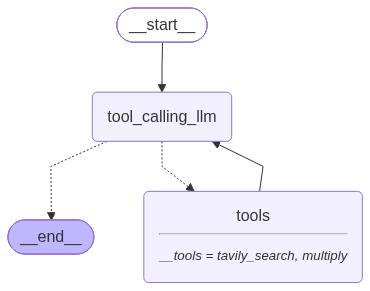

In [21]:
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
response = graph.invoke({"messages":"What is the recent AI News"})

In [23]:
response['messages'][-1].content

'**AI‑Industry Highlights –\u202fLate\u202fNovember\u202f2026 (last\u202f7\u202fdays)**  \n\nBelow is a concise roundup of the most newsworthy AI developments that have surfaced across the web in the past week. Each item is linked to the source where the information was reported.\n\n---\n\n### 1.\u202fBig‑Deal M&A Activity  \n\n| Company | Target / Deal | Deal Value | Why It Matters |\n|---------|---------------|------------|----------------|\n| **Shield\u202fAI** | Radar‑tech specialist **Echodyne** | **$5.3\u202fB** (plus a $2.5\u202fB funding round) | Gives Shield a high‑resolution, low‑latency radar capability for autonomous defence drones, tightening the link between AI‑driven autonomy and sensor hardware. |\n| **OpenAI** | **Pierre Computer Company** (code‑review & repo‑analysis tools) | Undisclosed, part of a broader strategic push | Extends OpenAI’s reach into the software‑development stack, positioning its models as “AI‑powered IDE assistants.” |\n| **Meta** | **Conductor** (c

In [24]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI News
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_4b038244-81a9-4814-9845-86bceca0e6b5)
 Call ID: fc_4b038244-81a9-4814-9845-86bceca0e6b5
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 billion.\n\nIn the software

In [25]:
response = graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})

for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3699d254-9af3-4f7e-825c-73e20779bd5d)
 Call ID: fc_3699d254-9af3-4f7e-825c-73e20779bd5d
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 b

## ReAct = Reasoning + Acting

- ReAct = Reason → Act → Observe → Repeat → Final Answer
- A ReAct agent is an AI agent that can decide what to do, use tools, observe their results, and continue until it can answer the user.
- Unlike a normal LLM, which generally generates an answer directly, a ReAct agent can use external tools to obtain information or perform actions.


Simple example

Imagine you ask an AI: "What is 25 × 40, and what is 10% of that amount?"

A normal LLM might calculate the answer itself.

## Adding Memory in Agentic Graph

- Memory allows an AI agent to remember information from previous interactions and use it in future conversations or workflow steps.

Imagine you're building an AI chatbot using LangGraph.

You ask:
User: My name is Rahul, and I'm learning Python.

The AI responds:
AI: Nice to meet you, Rahul!

Then you ask:
User: What is my name?

If the chatbot has no memory, it may respond: "I don't know your name."

But if the chatbot has memory, it can respond: "Your name is Rahul."

That's the basic purpose of memory.

## Two important types of Memory in LangGraph

LangGraph commonly uses two memory concepts: Short-term Memory and Long Term Memory

- Short-term memory : Remembers conversation state within a thread
- Long-term memory : Stores information that can be retrieved across conversations


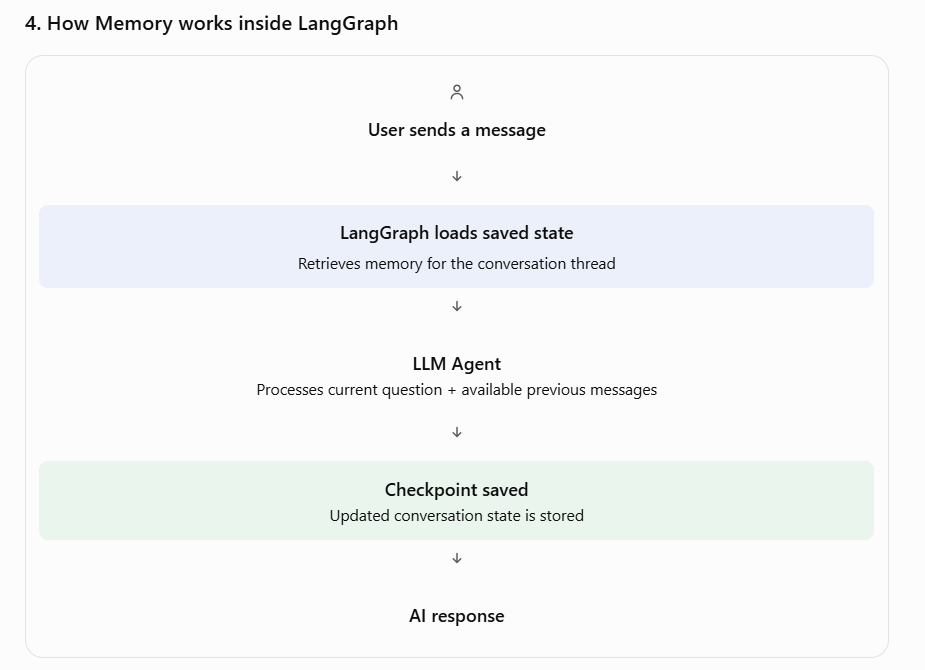

In [26]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
builder = StateGraph(State)

# Adding Nodes
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Adding Edges
builder.add_edge(START,'tool_calling_llm')
builder.add_conditional_edges(
    'tool_calling_llm',
    #if latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # if latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
) 
builder.add_edge('tools','tool_calling_llm')

graph = builder.compile(checkpointer=memory)

In [29]:
config = {"configurable":{"thread_id":"1"}}

response = graph.invoke({"messages":"Hey this is Kalyan"},config=config)
response['messages'][-1].content

'Hello Kalyan! 👋 How can I help you today?'

In [30]:
response = graph.invoke({"messages":"What is My name?, if you know my name what is the meaning of the name"},config=config)
response['messages'][-1].content

'Your name is **Kalyan**.\n\n### Meaning & Origin\n| Aspect | Details |\n|--------|---------|\n| **Language** | Primarily Sanskrit (used across many Indian languages) |\n| **Literal meaning** | “Welfare”, “auspicious”, “prosperous”, “beautiful”, “blessed”, “good” |\n| **Root word** | Derived from the Sanskrit word **कल्याण (kalyāṇa)**, which combines *kala* (time/period) and *yāna* (going, moving) – literally “moving toward a good time” or “progressing toward well‑being”. |\n| **Cultural significance** | Often used in Hindu philosophy and literature to denote a state of moral, spiritual, and material well‑being. It appears in phrases like *Kalyāṇa‑Mitra* (a good friend) and *Kalyāṇa‑Mitra* (a virtuous companion). |\n| **Common usage** | Used as a male given name in India, Nepal, Bangladesh, and among the Indian diaspora. It can also appear as a surname or part of place names (e.g., *Kalyan* city near Mumbai). |\n| **Related names** | Kalyani (female form), Kalyanaraman, Kalyanesh, Kaly

## Streaming Techniques

In [49]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [50]:
def superbot(state:State):
    return {'messages':[llm.invoke(state['messages'])]}

In [51]:
graph = StateGraph(State)

graph.add_node('Superbot',superbot)

graph.add_edge(START,'Superbot')
graph.add_edge('Superbot',END)

graph_builder = graph.compile(checkpointer=memory)

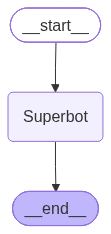

In [52]:
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [53]:
config1 = {'configurable':{"thread_id":"2"}}

graph_builder.invoke({"messages":"Hey this is Kalyan,I like watching Anime"},config=config1)

{'messages': [HumanMessage(content='Hey this is Kalyan,I like watching Anime', additional_kwargs={}, response_metadata={}, id='4cb4ab4e-6cf2-4e9c-a10b-3072bd15d56e'),
  AIMessage(content='Hey Kalyan! Nice to meet you. 🎉 Anime is such a fun world—there’s always something new to discover. Do you have any favorite series or genres? Are you into shōnen action, slice‑of‑life, sci‑fi, or maybe something a bit more off‑the‑beaten‑path? I’d love to hear what you’ve been watching lately! If you ever need recommendations, just let me know what vibes you’re in the mood for. 🚀✨', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "Hey this is Kalyan, I like watching Anime". Probably they want a response. There\'s no disallowed content. We can respond friendly, ask about favorite anime, etc. Should keep it conversational.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 81, 'total_tokens': 247, 'completion_time': 0.347746257, 'compl

- Streaming means receiving an AI model's response in smaller pieces as they become available, instead of waiting for the entire response to finish.

-  stream()

How it works
1. The user asks a question.
2. llm.stream() starts generating the answer.
3. The model returns chunks incrementally.
4. The for loop receives each chunk.
5. print() displays each chunk immediately.

astream()

What happens here?
- async def defines an asynchronous function.
- llm.astream() produces an asynchronous stream.
- async for receives the chunks.
- asyncio.run() starts the asynchronous program.
The output can look exactly like the synchronous version.

So why use astream()?

Because asynchronous programming allows your application to work on other tasks while waiting for I/O, such as network responses from an LLM API.

Stream mode	What you receive
- "messages" : 	LLM-generated message chunks
- "updates" : 	State updates after graph steps
- "values":	Full graph state snapshots

Update - which ever is the last message from AI/LLM only that gets dispalys

values - here both user question ai answer will gets added 

In [54]:
config1 = {'configurable':{"thread_id":"2"}}

# graph_builder.invoke({"messages":"Hey this is Kalyan,I like watching Anime"},config=config1)

for chunk in graph_builder.stream({"messages":"Hey This is Kalyan"},config=config1,stream_mode='updates'):
    print(chunk)


{'Superbot': {'messages': [AIMessage(content='Hey Kalyan! 👋 Great to hear from you again. What’s on your mind today? Got any new anime you’ve been binge‑watching, or are you looking for some fresh recommendations? Let me know—happy to chat about anything you like!', additional_kwargs={'reasoning_content': 'The user says "Hey This is Kalyan". Probably they want to continue conversation. We should respond friendly, ask about them, perhaps ask about anime preferences. Keep conversational.'}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 200, 'total_tokens': 300, 'completion_time': 0.207707514, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.007572176, 'prompt_tokens_details': None, 'queue_time': 0.36750014, 'total_time': 0.21527969}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_bb691ea66b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1fe14-3470-77

In [55]:
config1 = {'configurable':{"thread_id":"2"}}

# graph_builder.invoke({"messages":"Hey this is Kalyan,I like watching Anime"},config=config1)

for chunk in graph_builder.stream({"messages":"Hey This is Kalyan"},config=config1,stream_mode='values'):
    print(chunk)

{'messages': [HumanMessage(content='Hey this is Kalyan,I like watching Anime', additional_kwargs={}, response_metadata={}, id='4cb4ab4e-6cf2-4e9c-a10b-3072bd15d56e'), AIMessage(content='Hey Kalyan! Nice to meet you. 🎉 Anime is such a fun world—there’s always something new to discover. Do you have any favorite series or genres? Are you into shōnen action, slice‑of‑life, sci‑fi, or maybe something a bit more off‑the‑beaten‑path? I’d love to hear what you’ve been watching lately! If you ever need recommendations, just let me know what vibes you’re in the mood for. 🚀✨', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "Hey this is Kalyan, I like watching Anime". Probably they want a response. There\'s no disallowed content. We can respond friendly, ask about favorite anime, etc. Should keep it conversational.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 81, 'total_tokens': 247, 'completion_time': 0.347746257, 'complet

In [56]:
config1 = {'configurable':{"thread_id":"2"}}

# graph_builder.invoke({"messages":"Hey this is Kalyan,I like watching Anime"},config=config1)

for chunk in graph_builder.stream({"messages":"Hey This is Kalyan"},config=config1,stream_mode='messages'):
    print(chunk)

(AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a1fe14-f7d0-71a0-87cc-a14412c6f88e', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'thread_id': '2', 'ls_integration': 'langchain_chat_model', 'langgraph_step': 10, 'langgraph_node': 'Superbot', 'langgraph_triggers': ('branch:to:Superbot',), 'langgraph_path': ('__pregel_pull', 'Superbot'), 'langgraph_checkpoint_ns': 'Superbot:f7e089ee-49b8-60bd-8cd9-84ba11005984', 'checkpoint_ns': 'Superbot:f7e089ee-49b8-60bd-8cd9-84ba11005984', 'ls_provider': 'groq', 'ls_model_name': 'openai/gpt-oss-120b', 'ls_model_type': 'chat', 'ls_temperature': 0.7, 'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.5.0', 'langchain-groq': '1.2.0'}})
(AIMessageChunk(content='', additional_kwargs={'reasoning_content': 'The'}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a1fe14-f7d0-71a0-87cc-a14412c6f88e', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'th